# Proyecto final: priorizar pacientes con alto riesgo de ACV para un programa de prevención

**Estudiante:** Sergio Alfredo Junca Valero (trabajo individual) · ST1613 Aprendizaje de Máquina Aplicado, Universidad EAFIT

**Escenario (supuesto, no es una EPS real):** un programa de prevención cardiovascular solo puede citar cada mes a una parte de sus afiliados. Hoy los escoge con la regla **"edad ≥ 60 o hipertensión"**.
**Pregunta:** ¿se puede ordenar a los pacientes por riesgo de ACV mejor que con esa regla, de modo que el programa capte al menos el 80 % de los casos citando a menos personas?
**Datos:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle). Cada fila es un paciente; `stroke` = 1 si ya tuvo un accidente cerebrovascular (ACV).

**Tres métricas, cada una con su trabajo:**
1. **PR-AUC** (*average precision*): solo para ajustar hiperparámetros. Con 4.9 % de casos, el accuracy no sirve: un modelo que siempre diga "no ACV" acierta el 95 %.
2. **Casos captados con las mismas citas que la regla**: para elegir el modelo ganador. Es la pregunta del negocio.
3. **Umbral con recall ≥ 0.80**: para operar. Dejar a un paciente en riesgo fuera de la lista cuesta más que una cita de más.

**Respuesta corta.** Gana la regresión logística. Con las mismas citas que la regla capta unos 2 casos más de cada 40 (+1.75; supera a la regla en 15 de 20 evaluaciones). Con recall de 0.80 cita al 29 % de los afiliados en lugar del 31 %. En la prueba sellada (50 casos) obtiene recall 0.80 y +1 caso con las mismas citas (IC 95 %: 0 a 4): una mejora real pero moderada, que la prueba sola no alcanza a demostrar. **Sesgo por edad (sección 9):** con un umbral por grupo de edad, el recall en menores de 60 sube de 0.29 a 0.79 en la CV anidada, a cambio de citar al 34.5 % en lugar del 29.1 %.

**Cómo leerlo:** cada sección dice qué se hace y por qué; **Lectura** resume lo que muestran los resultados. Corre de cero en unos 3 minutos (la validación cruzada anidada es lo más lento) y las semillas están fijas.

In [1]:
# Instala lo que falte (Colab no trae kagglehub, imbalanced-learn ni shap por defecto)
import importlib.util, subprocess, sys
faltan = [p for p, m in [('kagglehub', 'kagglehub'), ('imbalanced-learn', 'imblearn'), ('shap', 'shap')]
          if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan], check=True)

import json, os, time, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'   # los procesos de joblib heredan esto y no llenan la salida de avisos
warnings.filterwarnings('ignore')
import kagglehub
import numpy as np
import pandas as pd
import shap
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from joblib import Parallel, delayed
from matplotlib import dates as mdates, pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import (GridSearchCV, ParameterGrid, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

os.makedirs('fig', exist_ok=True)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, ROJO, GRIS = '#2b6cb0', '#c53030', '#a0aec0'
R = {}   # cifras que alimentan el documento y la web; se guardan al final en fig/resultados.json

## 1. Datos y partición
**Por qué:** se parte 80/20 **antes** de mirar nada más y con `stratify=y`, para que entrenamiento y prueba conserven el 4.9 % de casos. La prueba queda sellada hasta la sección 6: modelo, hiperparámetros y umbral se deciden solo con entrenamiento. Se eliminan `id` (identificador único: el modelo memorizaría pacientes) y el único registro con `gender = Other` (no permite aprender nada).

In [2]:
path = kagglehub.dataset_download('fedesoriano/stroke-prediction-dataset')   # público, sin credenciales
df = pd.read_csv(os.path.join(path, 'healthcare-dataset-stroke-data.csv')).drop(columns='id')
R['datos'] = {'filas_csv': len(df), 'nulos_bmi': int(df['bmi'].isna().sum()),
              'unknown_fumador': round((df['smoking_status'] == 'Unknown').mean(), 4)}
df = df[df['gender'] != 'Other']   # 1 registro: no permite aprender nada
X, y = df.drop(columns='stroke'), df['stroke']

# Se parte ANTES de mirar nada más: la prueba (20 %) queda sellada hasta la sección 6
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f'Total {len(df)} | ACV {y.mean():.2%}')
print(f'Entrenamiento {len(X_tr)} ({y_tr.sum()} casos) | Prueba {len(X_te)} ({y_te.sum()} casos, sellada)')
R['datos'].update(filas=len(df), casos=int(y.sum()), prevalencia=round(y.mean(), 4), n_train=len(X_tr),
                  casos_train=int(y_tr.sum()), n_test=len(X_te), casos_test=int(y_te.sum()))

Total 5109 | ACV 4.87%
Entrenamiento 4087 (199 casos) | Prueba 1022 (50 casos, sellada)


## 2. Exploración mínima (solo entrenamiento)
**Por qué:** saber si los datos contienen señal para estimar P(y|X) antes de modelar. Se explora solo el entrenamiento, así que "la prueba no se tocó" es literal.

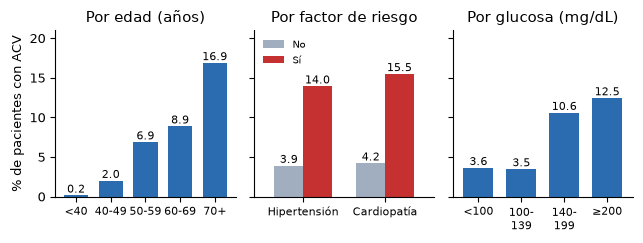

Tasa por edad (%): {'<40': 0.2, '40-49': 2.0, '50-59': 6.9, '60-69': 8.9, '70+': 16.9}
Tasa por factor (%): {'No': {'Hipertensión': 3.9, 'Cardiopatía': 4.2}, 'Sí': {'Hipertensión': 14.0, 'Cardiopatía': 15.5}}
Tasa por glucosa (%): {'<100': 3.6, '100-\n139': 3.5, '140-\n199': 10.6, '≥200': 12.5}
Mediana de bmi con ACV / sin ACV: {0: 27.9, 1: 29.9}
Unknown en tabaquismo: 30.2%; de ellos, menores de 18: 44.4%; tasa de ACV 3.1% frente a 5.6%
Mayores |correlación| con stroke: {'age': 0.244, 'hypertension': 0.137, 'avg_glucose_level': 0.129}


In [3]:
tr = X_tr.assign(stroke=y_tr)   # el EDA usa solo entrenamiento: así "la prueba no se tocó" es literal
edad = tr.groupby(pd.cut(tr['age'], [0, 40, 50, 60, 70, 83], labels=['<40', '40-49', '50-59', '60-69', '70+']),
                  observed=True)['stroke'].mean() * 100
riesgo = pd.DataFrame({'No': [tr.loc[tr[c] == 0, 'stroke'].mean() for c in ('hypertension', 'heart_disease')],
                       'Sí': [tr.loc[tr[c] == 1, 'stroke'].mean() for c in ('hypertension', 'heart_disease')]},
                      index=['Hipertensión', 'Cardiopatía']) * 100
glucosa = tr.groupby(pd.cut(tr['avg_glucose_level'], [0, 100, 140, 200, 300], right=False,
                            labels=['<100', '100-\n139', '140-\n199', '≥200']), observed=True)['stroke'].mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.5), sharey=True)
for ax, (titulo, s, color) in zip(axes, [('Por edad (años)', edad, AZUL), ('Por factor de riesgo', riesgo, [GRIS, ROJO]),
                                         ('Por glucosa (mg/dL)', glucosa, AZUL)]):
    s.plot.bar(ax=ax, color=color, width=0.7)
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.1f', fontsize=8)
    ax.set(title=titulo, xlabel='')
    ax.tick_params(axis='x', rotation=0, labelsize=8)
axes[1].legend(title=None, fontsize=7.5, frameon=False, loc='upper left')
axes[0].set(ylabel='% de pacientes con ACV', ylim=(0, 21))
plt.tight_layout(); plt.savefig('fig/f1_tasas.png', dpi=200); plt.show()

unk = tr['smoking_status'] == 'Unknown'
corr = pd.get_dummies(tr, dtype=float).corr()['stroke'].drop('stroke').abs().nlargest(3).round(3)
print('Tasa por edad (%):', edad.round(1).to_dict())
print('Tasa por factor (%):', riesgo.round(1).to_dict())
print('Tasa por glucosa (%):', glucosa.round(1).to_dict())
print('Mediana de bmi con ACV / sin ACV:', tr.groupby('stroke')['bmi'].median().round(1).to_dict())
print(f"Unknown en tabaquismo: {unk.mean():.1%}; de ellos, menores de 18: {(tr.loc[unk, 'age'] < 18).mean():.1%}; "
      f"tasa de ACV {tr.loc[unk, 'stroke'].mean():.1%} frente a {tr.loc[~unk, 'stroke'].mean():.1%}")
print('Mayores |correlación| con stroke:', corr.to_dict())
R['eda'] = {'tasa_edad': edad.round(2).to_dict(), 'tasa_factor': riesgo.round(2).to_dict(),
            'tasa_glucosa': {k.replace('\n', ''): v for k, v in glucosa.round(2).to_dict().items()},
            'corr_max': corr.to_dict()}

**Lectura.**
- **La edad domina:** la tasa de ACV pasa de 0.2 % en menores de 40 años a 16.9 % en mayores de 70. Es la correlación más alta con `stroke` (0.244), y ninguna llega a 0.25: hay señal, pero débil y no lineal; por eso se prueban también modelos de árboles.
- **Hipertensión y cardiopatía** multiplican el riesgo por 3.6 (14.0 % frente a 3.9 %) y por 3.7 (15.5 % frente a 4.2 %). **La glucosa separa desde 140 mg/dL** (10.6 % y 12.5 %, frente a 3.6 % y 3.5 % por debajo de 140).
- **El IMC casi no discrimina** (mediana de 29.9 con ACV y 27.9 sin ACV).
- **`Unknown` en tabaquismo (30.2 %) no es un nulo cualquiera:** el 44.4 % son menores de 18 años y su tasa de ACV es menor (3.1 % frente a 5.6 %). **Decisión:** se deja como categoría propia; borrarla quitaría casi un tercio de la base.
- **`bmi` tiene 201 nulos (3.9 %):** se imputan con la mediana dentro del *pipeline* (sección 3), ajustada solo con cada entrenamiento.

## 3. Línea base de negocio y familias de modelos
**Por qué una regla como línea base:** un modelo solo vale lo que mejora lo que ya existe. La regla no se entrena; se evalúa sobre los mismos datos.

**Por qué un `Pipeline`:** la imputación, el escalado y la codificación se ajustan dentro de cada *fold*, solo con su entrenamiento: nada de lo que está afuera se filtra. SMOTE usa el `Pipeline` de `imblearn` por lo mismo: sobremuestrea solo el entrenamiento de cada *fold*, nunca antes de partir (el error de Tazin et al., 2021).

| Iteración | Familia | Por qué | Configuraciones |
|---|---|---|---|
| 1 | Regresión logística (`class_weight`) | Referencia explicable: cada coeficiente se lee | 10 (`C` × L1/L2) |
| 1 | Regresión logística + SMOTE | ¿Sirve crear casos sintéticos en vez de pesar los reales? | 10 |
| 1 | kNN + SMOTE | Referencia por distancias | 10 (`k` × pesos) |
| 2 | Random forest | Captura interacciones (edad × glucosa) | 15 (`min_samples_leaf` × `max_features`) |
| 2 | Gradient boosting | Ensamble secuencial, suele ganar en tablas | 12 (tasa × profundidad × iteraciones) |

No se usan redes profundas: hay solo 199 casos de entrenamiento y, con estas variables, una red no superó a la regresión logística en AUC (Kokkotis et al., 2022).

In [4]:
regla = lambda d: ((d['age'] >= 60) | (d['hypertension'] == 1)).to_numpy()   # regla actual de la EPS (supuesto)
print(f"Regla en entrenamiento: cita {regla(X_tr).mean():.1%} y capta {regla(X_tr)[y_tr == 1].mean():.1%} de los casos")

num = ['age', 'avg_glucose_level', 'bmi']
cat = [c for c in X.columns if c not in num]
prep = ColumnTransformer([
    # imputar con la mediana (no la mueven los extremos) y escalar: las escalas pasan a ser comparables
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), num),
    # categorías sin orden: una columna 0/1 por categoría
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
])


def pipe(modelo, smote=False):
    # El Pipeline de imblearn aplica SMOTE solo al entrenamiento de cada fold (nunca antes de partir): sin fuga de datos
    return Pipeline([('prep', prep)] + ([('smote', SMOTE(random_state=0))] if smote else []) + [('m', modelo)])


C = [0.001, 0.01, 0.1, 1, 10]
familias = {   # de la más simple a la más compleja; el orden se usa para desempatar
    'Regresión logística': (pipe(LogisticRegression(class_weight='balanced', solver='liblinear')),
                            {'m__C': C, 'm__penalty': ['l1', 'l2']}, 1),
    'Regresión logística + SMOTE': (pipe(LogisticRegression(solver='liblinear'), smote=True),
                                    {'m__C': C, 'm__penalty': ['l1', 'l2']}, 1),
    'kNN + SMOTE': (pipe(KNeighborsClassifier(), smote=True),
                    {'m__n_neighbors': [5, 15, 25, 51, 101], 'm__weights': ['uniform', 'distance']}, 1),
    'Random forest': (pipe(RandomForestClassifier(200, class_weight='balanced_subsample', random_state=0)),
                      {'m__min_samples_leaf': [5, 10, 20, 40, 80], 'm__max_features': ['sqrt', 0.3, 0.5]}, 2),
    'Gradient boosting': (pipe(HistGradientBoostingClassifier(class_weight='balanced', random_state=0)),
                          {'m__learning_rate': [0.03, 0.1, 0.3], 'm__max_depth': [2, 3], 'm__max_iter': [100, 300]}, 2),
}
configs = {n: len(ParameterGrid(g)) for n, (_, g, _) in familias.items()}
print('Configuraciones por familia:', configs)

Regla en entrenamiento: cita 30.8% y capta 77.9% de los casos
Configuraciones por familia: {'Regresión logística': 10, 'Regresión logística + SMOTE': 10, 'kNN + SMOTE': 10, 'Random forest': 15, 'Gradient boosting': 12}


## 4. Iteraciones 1 y 2: validación cruzada anidada y repetida
**Por qué anidada:** el ciclo **interno** (5 folds) elige los hiperparámetros con PR-AUC; el ciclo **externo** (5 folds × 4 repeticiones = 20 evaluaciones) mide con datos que no participaron en esa elección. Así la estimación no queda inflada por haber probado muchas configuraciones. Cada evaluación externa tiene ~817 pacientes y ~40 casos, parecido a la prueba real (1 022 y 50), y en ella se fija además el umbral (recall ≥ 0.80 fuera de fold interno) sin mirar el fold externo.

**Por qué repetida:** con 40 casos por evaluación, un caso más o menos mueve el recall 2.5 puntos. Veinte evaluaciones permiten ver el ruido en vez de adivinarlo.

**Cómo se elige el ganador (regla fijada en el anteproyecto, antes de ver estos resultados):** el que capte más casos con las citas de la regla; si otros quedan a menos de **una desviación estándar** del mejor, gana el más simple.

In [5]:
def umbral_recall(y_true, score, minimo=0.80):
    """Umbral más alto que logra recall >= minimo (el que cita a menos pacientes)."""
    pos = np.sort(score[np.asarray(y_true) == 1])[::-1]
    return pos[int(np.ceil(minimo * len(pos))) - 1]


def top_n(score, n):
    """Marca a los n pacientes de mayor puntaje: el mismo número de citas que la regla."""
    m = np.zeros(len(score), bool)
    m[np.argsort(-score, kind='stable')[:n]] = True
    return m


def fold_externo(k, a, b):
    Xa, ya, Xb, yb = X_tr.iloc[a], y_tr.iloc[a], X_tr.iloc[b], y_tr.iloc[b].to_numpy()
    r = regla(Xb)
    interno = StratifiedKFold(5, shuffle=True, random_state=k)
    filas = []
    for nombre, (modelo, grilla, _) in familias.items():
        g = GridSearchCV(modelo, grilla, scoring='average_precision', cv=interno).fit(Xa, ya)   # ciclo interno
        oof = cross_val_predict(g.best_estimator_, Xa, ya, cv=interno, method='predict_proba')[:, 1]
        t = umbral_recall(ya, oof)                          # umbral elegido sin mirar el fold externo
        s = g.best_estimator_.predict_proba(Xb)[:, 1]       # ciclo externo: datos que no participaron en nada
        cita, top = s >= t, top_n(s, r.sum())
        filas.append({'fold': k, 'familia': nombre, 'params': str(g.best_params_),
                      'pr_auc': average_precision_score(yb, s), 'roc_auc': roc_auc_score(yb, s),
                      'recall': cita[yb == 1].mean(), 'precision': yb[cita].mean(), 'citados': cita.mean(),
                      'recall_regla': r[yb == 1].mean(), 'precision_regla': yb[r].mean(), 'citados_regla': r.mean(),
                      'casos_extra': int(top[yb == 1].sum() - r[yb == 1].sum()), 'casos': int(yb.sum())})
    return filas


externo = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=1)   # 20 evaluaciones de ~817 pacientes
t0 = time.time()
filas = Parallel(n_jobs=-1)(delayed(fold_externo)(k, a, b) for k, (a, b) in enumerate(externo.split(X_tr, y_tr)))
cv = pd.DataFrame([f for fs in filas for f in fs])
print(f'CV anidada: {time.time() - t0:.0f} s')

orden = list(familias)
resumen = cv.groupby('familia').agg(
    pr_auc=('pr_auc', 'mean'), roc_auc=('roc_auc', 'mean'), recall=('recall', 'mean'), precision=('precision', 'mean'), citados=('citados', 'mean'),
    extra=('casos_extra', 'mean'), extra_sd=('casos_extra', 'std'), supera=('casos_extra', lambda v: (v > 0).mean())
).loc[orden]
resumen.insert(0, 'configs', [configs[n] for n in orden])
regla_cv = {'recall': cv.recall_regla.mean(), 'precision': cv.precision_regla.mean(), 'citados': cv.citados_regla.mean(),
            'casos_por_fold': cv.casos.mean()}
pd.set_option('display.width', 200)
print(resumen.round(3).to_string())
print('Regla en los mismos folds:', {k: round(v, 3) for k, v in regla_cv.items()})

# Ganador: el que más casos capta con las citas de la regla; si otros quedan a menos de 1 desviación estándar, el más simple
mejor = resumen['extra'].idxmax()
empatados = resumen[resumen['extra'] >= resumen.loc[mejor, 'extra'] - resumen.loc[mejor, 'extra_sd']].index
ganador = min(empatados, key=orden.index)
por_pr_auc = resumen['pr_auc'].idxmax()
print(f'Más casos extra: {mejor} | a menos de 1 DE de él: {list(empatados)} | GANADOR (el más simple): {ganador}')
print(f'Mayor PR-AUC: {por_pr_auc}')
R['cv'] = {'folds': 20, 'casos_por_fold': round(regla_cv['casos_por_fold'], 1), 'regla': regla_cv, 'ganador': ganador,
           'mejor_casos_extra': mejor, 'mejor_pr_auc': por_pr_auc, 'empatados': list(empatados),
           'familias': {n: {**resumen.loc[n].to_dict(), 'por_fold': cv[cv.familia == n]['casos_extra'].tolist()}
                        for n in orden}}

CV anidada: 85 s
                             configs  pr_auc  roc_auc  recall  precision  citados  extra  extra_sd  supera
familia                                                                                                   
Regresión logística               10   0.185    0.841   0.796      0.134    0.291   1.75     1.552    0.75
Regresión logística + SMOTE       10   0.182    0.838   0.795      0.132    0.295   1.55     1.820    0.75
kNN + SMOTE                       10   0.139    0.797   0.789      0.112    0.342  -1.60     2.683    0.15
Random forest                     15   0.193    0.844   0.812      0.140    0.282   2.40     1.667    0.95
Gradient boosting                 12   0.197    0.830   0.849      0.118    0.352   1.30     2.618    0.55
Regla en los mismos folds: {'recall': np.float64(0.779), 'precision': np.float64(0.124), 'citados': np.float64(0.308), 'casos_por_fold': np.float64(39.8)}
Más casos extra: Random forest | a menos de 1 DE de él: ['Regresión logística',

**Lectura.**
- **Con las mismas citas que la regla, todos los modelos de buen desempeño captan más casos.** Regresión logística: +1.75 casos de ~40 (supera a la regla en 15 de 20 evaluaciones); *random forest*: +2.40 (19 de 20); *gradient boosting*: +1.30 (11 de 20). La mejora es real pero moderada.
- **kNN no supera a la regla** (−1.60; solo 3 de 20), y **SMOTE no ayuda** a la regresión logística (+1.55 frente a +1.75): pesar los casos reales basta.
- **Tres criterios, tres modelos distintos.** El PR-AUC habría escogido *gradient boosting* (0.197), justo el que más cita (35.2 % de los pacientes para llegar a recall 0.85) y que capta solo +1.30. La métrica de negocio señala al *random forest* (+2.40). Y la regla de parsimonia lleva a la regresión logística: el *random forest* capta 0.65 casos más, bastante menos que una desviación estándar (1.67), y esa diferencia no se distingue del ruido.
- **Decisión: gana la regresión logística.** Es la más simple, la que el equipo médico puede leer coeficiente a coeficiente, y no es peor que las demás dentro del ruido.

## 5. Modelo final y umbral de operación
**Por qué:** se reajusta la búsqueda de hiperparámetros con todo el 80 % de entrenamiento y se obtienen predicciones **fuera de fold** (`cross_val_predict`: cada paciente se puntúa con un modelo que no lo vio). Con ellas se elige el umbral más alto que logre recall ≥ 0.80, es decir, el que cita a menos personas. También se calcula la tabla de **puntos de operación**: lo que cuesta cada punto de recall, para que quien decide mueva el umbral según su capacidad de citas.

In [6]:
interno = StratifiedKFold(5, shuffle=True, random_state=42)
modelo, grilla, _ = familias[ganador]
g = GridSearchCV(modelo, grilla, scoring='average_precision', cv=interno).fit(X_tr, y_tr)   # se reajusta con todo el 80 %
final = g.best_estimator_
print('Hiperparámetros elegidos:', g.best_params_)
# ¿La C elegida está en el borde de la grilla? Si el PR-AUC es casi plano, la regularización casi no importa
plano = pd.DataFrame(g.cv_results_).groupby(['param_m__penalty', 'param_m__C'])['mean_test_score'].mean().round(3).unstack(0)
print(plano.to_string())
oof =cross_val_predict(final, X_tr, y_tr, cv=interno, method='predict_proba')[:, 1]   # predicciones fuera de fold
ytr = y_tr.to_numpy()
t = umbral_recall(ytr, oof)

r_tr = regla(X_tr)
filas = []
for objetivo in [0.70, 0.75, 0.80, 0.85, 0.90]:
    u = umbral_recall(ytr, oof, objetivo)
    c = oof >= u
    filas.append({'recall_objetivo': objetivo, 'umbral': u, 'recall': c[ytr == 1].mean(), 'precision': ytr[c].mean(), 'citados': c.mean()})
operacion = pd.DataFrame(filas)
print(operacion.round(3).to_string(index=False))
print(f"Regla: recall {r_tr[ytr == 1].mean():.3f}, precisión {ytr[r_tr].mean():.3f}, citados {r_tr.mean():.3f}")
print(f'Umbral de operación (recall >= 0.80 fuera de fold): {t:.4f}')
R['final'] = {'params': {k: v for k, v in g.best_params_.items()}, 'umbral': round(float(t), 4),
              'operacion': operacion.round(4).to_dict('records'),
              'regla_train': {'recall': r_tr[ytr == 1].mean(), 'precision': ytr[r_tr].mean(), 'citados': r_tr.mean()}}

Hiperparámetros elegidos: {'m__C': 10, 'm__penalty': 'l2'}
param_m__penalty     l1     l2
param_m__C                    
0.001             0.049  0.184
0.010             0.189  0.191
0.100             0.189  0.192
1.000             0.192  0.192
10.000            0.192  0.193
 recall_objetivo  umbral  recall  precision  citados
            0.70   0.583   0.704      0.145    0.236
            0.75   0.532   0.754      0.137    0.269
            0.80   0.504   0.804      0.138    0.285
            0.85   0.434   0.854      0.126    0.331
            0.90   0.359   0.905      0.113    0.389
Regla: recall 0.779, precisión 0.123, citados 0.308
Umbral de operación (recall >= 0.80 fuera de fold): 0.5040


**Lectura.**
- **C = 10 está en el borde de la grilla, pero no importa:** con L2 el PR-AUC de entrenamiento es plano desde C = 0.01 (0.191 a 0.193). Con 4 087 pacientes y unas 20 columnas, la regularización casi no cambia el modelo.
- **Umbral de operación: 0.504.** Fuera de fold cita al 28.5 % de los pacientes con recall 0.804 y precisión 0.138. La regla cita al 30.8 % con recall 0.779: el modelo capta más casos con 2.3 puntos menos de citas.
- **Cada punto de recall cuesta citas, y cuesta más al subir:** de 0.80 a 0.90 hay que citar del 28.5 % al 38.9 %. Esa tabla, no un número único, es lo que se le entrega a quien decide.

## 6. Prueba: una sola evaluación
**Por qué una sola vez:** si la prueba se mira para decidir algo, deja de ser prueba. Aquí el modelo, sus hiperparámetros y el umbral ya están fijos. Con 50 casos, un caso mueve el recall 2 puntos, así que además del valor puntual se reporta un intervalo de confianza del 95 % por *bootstrap* (1 000 remuestreos de la prueba con reemplazo; el 95 % central de los valores recalculados).

recall           0.800   IC 95 %: 0.689 a 0.902
precision        0.135   IC 95 %: 0.099 a 0.174
citados          0.290   IC 95 %: 0.262 a 0.315
casos_extra      1.000   IC 95 %: 0.000 a 4.000
recall_regla     0.780   IC 95 %: 0.667 a 0.887
precision_regla  0.122   IC 95 %: 0.089 a 0.157
citados_regla    0.313   IC 95 %: 0.287 a 0.340
Casos en prueba: 50 | ROC-AUC 0.84 | PR-AUC 0.26 (azar: 0.049 )
Mejora con las mismas citas: la regla capta 39 de 50 | el modelo 40


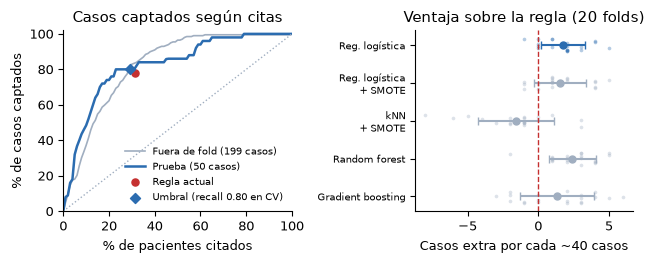

In [7]:
# ---- LA PRUEBA SE ABRE AQUÍ, UNA SOLA VEZ. Desde esta celda no se vuelve a ajustar nada. ----
s_te, yte, r_te = final.predict_proba(X_te)[:, 1], y_te.to_numpy(), regla(X_te)


def medir(idx):
    s, yy, rr = s_te[idx], yte[idx], r_te[idx]
    c, top = s >= t, top_n(s, rr.sum())
    return {'recall': c[yy == 1].mean(), 'precision': yy[c].mean(), 'citados': c.mean(),
            'recall_regla': rr[yy == 1].mean(), 'precision_regla': yy[rr].mean(), 'citados_regla': rr.mean(),
            'casos_extra': int(top[yy == 1].sum() - rr[yy == 1].sum()), 'casos': int(yy.sum())}


punto = medir(np.arange(len(yte)))
rng = np.random.default_rng(0)
boot = pd.DataFrame([medir(rng.integers(0, len(yte), len(yte))) for _ in range(1000)])   # 1000 remuestreos con reemplazo
ic = boot.quantile([0.025, 0.975])
for k in ['recall', 'precision', 'citados', 'casos_extra', 'recall_regla', 'precision_regla', 'citados_regla']:
    print(f'{k:16s} {punto[k]:.3f}   IC 95 %: {ic[k].iloc[0]:.3f} a {ic[k].iloc[1]:.3f}')
print('Casos en prueba:', punto['casos'], '| ROC-AUC', round(roc_auc_score(yte, s_te), 3),
      '| PR-AUC', round(average_precision_score(yte, s_te), 3), '(azar:', round(yte.mean(), 3), ')')
print('Mejora con las mismas citas: la regla capta', int(r_te[yte == 1].sum()), 'de', punto['casos'],
      '| el modelo', int(top_n(s_te, r_te.sum())[yte == 1].sum()))
R['prueba'] = {'puntual': punto, 'ic': {k: [ic[k].iloc[0], ic[k].iloc[1]] for k in ic.columns},
               'roc_auc': roc_auc_score(yte, s_te), 'pr_auc': average_precision_score(yte, s_te),
               'p_extra_positivo': (boot['casos_extra'] > 0).mean()}

# Curva de captura: % de casos captados al citar al x % con mayor puntaje
def captura(score, yv, n=101):
    acum = np.cumsum(yv[np.argsort(-score, kind='stable')]) / yv.sum()
    return np.interp(np.linspace(0, 1, n), np.r_[0, np.arange(1, len(yv) + 1) / len(yv)], np.r_[0, acum])


def precision_curva(score, yv, n=101):   # precisión al citar al x % con mayor puntaje
    orden_ = np.argsort(-score, kind='stable')
    k = np.arange(1, len(yv) + 1)
    return np.interp(np.linspace(0, 1, n)[1:], k / len(yv), np.cumsum(yv[orden_]) / k)


R['curvas'] = {'x': np.linspace(0, 1, 101), 'prueba': captura(s_te, yte), 'fuera_de_fold': captura(oof, ytr),
               'precision_fuera_de_fold': precision_curva(oof, ytr)}

fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 2.7), gridspec_kw={'width_ratios': [1.05, 1]})
a.plot(R['curvas']['x'] * 100, np.array(R['curvas']['fuera_de_fold']) * 100, color=GRIS, lw=1.2, label='Fuera de fold (199 casos)')
a.plot(R['curvas']['x'] * 100, np.array(R['curvas']['prueba']) * 100, color=AZUL, lw=1.8, label='Prueba (50 casos)')
a.plot([0, 100], [0, 100], ls=':', color=GRIS, lw=1)
a.scatter(punto['citados_regla'] * 100, punto['recall_regla'] * 100, color=ROJO, zorder=3, s=26, label='Regla actual')
a.scatter(punto['citados'] * 100, punto['recall'] * 100, color=AZUL, zorder=3, s=26, marker='D', label='Umbral (recall 0.80 en CV)')
a.set(xlabel='% de pacientes citados', ylabel='% de casos captados', title='Casos captados según citas', xlim=(0, 100), ylim=(0, 102))
a.legend(fontsize=7, frameon=False, loc='lower right')
for i, n in enumerate(orden):   # puntos grises = un fold; marcador = promedio; barra = ±1 DE
    d = cv[cv.familia == n]['casos_extra']
    col = AZUL if n == ganador else GRIS
    b.scatter(d, i + np.random.default_rng(i).uniform(-0.18, 0.18, len(d)), s=7, color=col, alpha=0.35, lw=0)
    b.errorbar(d.mean(), i, xerr=d.std(), fmt='o', color=col, capsize=3, ms=5)
b.axvline(0, color=ROJO, lw=1, ls='--')
b.set_yticks(range(len(orden)), [n.replace('Regresión logística', 'Reg. logística').replace(' + ', '\n+ ') for n in orden], fontsize=7.5)
b.invert_yaxis()
b.set(xlabel='Casos extra por cada ~40 casos', title='Ventaja sobre la regla (20 folds)')
plt.tight_layout(); plt.savefig('fig/f3_resultados.png', dpi=200); plt.show()

**Lectura.**
- **Recall 0.80 (40 de 50 casos; IC 95 %: 0.69 a 0.90) citando al 29.0 % de los pacientes.** La regla, con 31.3 % de citas, capta 39 de 50 (0.78). El recall coincide con el objetivo fijado fuera de fold.
- **Con las mismas citas que la regla, el modelo capta 40 casos y la regla 39: +1 (IC 95 %: 0 a 4).** Coincide en signo con la validación cruzada anidada (+1.75), pero con 50 casos la prueba sola **no puede demostrar** la ventaja: el intervalo incluye el cero. Por eso la estimación principal es la anidada (20 evaluaciones) y la prueba se reporta con su incertidumbre.
- **ROC-AUC 0.84 (0.841 en la CV anidada; 0.833 en Kokkotis et al. con las mismas variables) y PR-AUC 0.26** frente a 0.049 del azar. La precisión, 0.135 (IC 95 %: 0.10 a 0.17), significa que unos 86 de cada 100 citados no tendrán un ACV: la cita se comunica como prevención, no como diagnóstico.

## 7. ¿A quién deja fuera? Desempeño por grupo
**Por qué:** una lista que funciona en promedio puede fallarle siempre a las mismas personas. Se mide el recall por sexo, zona y edad con las predicciones fuera de fold (199 casos, más estables) y se contrasta con la prueba (50 casos). Con tan pocos casos por grupo la comparación es **descriptiva**, no concluyente. Se agrega el recall de la regla para ver quién gana o pierde frente a ella.

In [8]:
def por_grupo(score, yv, Xg):
    c, rr = score >= t, regla(Xg)
    grupos = {'Sexo': Xg['gender'].to_numpy(), 'Zona': Xg['Residence_type'].to_numpy(),
              'Edad': pd.cut(Xg['age'], [0, 18, 60, 120], right=False, labels=['<18', '18-59', '≥60']).astype(str).to_numpy(),
              'Adultos': np.where(Xg['age'] >= 18, 'adultos (≥18)', 'menores')}
    filas = []
    for var, v in grupos.items():
        for val in sorted(set(v)):
            m = v == val
            filas.append({'grupo': var, 'valor': val, 'n': int(m.sum()), 'casos': int(yv[m].sum()),
                          'recall': c[m & (yv == 1)].sum() / yv[m].sum() if yv[m].sum() else np.nan,
                          'recall_regla': rr[m & (yv == 1)].sum() / yv[m].sum() if yv[m].sum() else np.nan,
                          'citados': c[m].mean(), 'citados_regla': rr[m].mean()})
    return pd.DataFrame(filas)


g_oof, g_te = por_grupo(oof, ytr, X_tr), por_grupo(s_te, yte, X_te)
grupos = g_oof.merge(g_te, on=['grupo', 'valor'], suffixes=('_cv', '_prueba'))
print(grupos[['grupo', 'valor', 'casos_cv', 'recall_cv', 'recall_regla_cv', 'citados_cv', 'citados_regla_cv',
              'casos_prueba', 'recall_prueba', 'recall_regla_prueba']].round(3).to_string(index=False))
R['grupos'] = grupos.to_dict('records')

  grupo         valor  casos_cv  recall_cv  recall_regla_cv  citados_cv  citados_regla_cv  casos_prueba  recall_prueba  recall_regla_prueba
   Sexo        Female       112      0.759            0.768       0.283             0.302            29          0.828                0.828
   Sexo          Male        87      0.862            0.793       0.286             0.316            21          0.762                0.714
   Zona         Rural        91      0.780            0.780       0.266             0.303            23          0.696                0.696
   Zona         Urban       108      0.824            0.778       0.303             0.313            27          0.889                0.852
   Edad         18-59        55      0.345            0.218       0.063             0.068            11          0.182                0.091
   Edad           <18         1      0.000            0.000       0.000             0.001             1          0.000                0.000
   Edad           ≥6

**Lectura.**
- **Por edad está la diferencia.** El modelo cita al 92.4 % de los mayores de 60 y capta el 98.6 % de sus casos (la regla cita al 100 % y capta el 100 %): ahorra citas entre los mayores de menor riesgo. En 18 a 59 años capta el **34.5 %** de los casos citando al 6.3 %, frente al 21.8 % de la regla (6.8 % de citas). El modelo apunta mejor, no cita más: ahorra citas entre los mayores de menor riesgo y, entre los jóvenes, acierta con menos citas. **Pero sigue dejando fuera a casi dos de cada tres casos menores de 60** (en la prueba capta 2 de 11): el médico debe poder agregar pacientes a la lista.
- **Sexo y zona: sin brecha concluyente.** Fuera de fold el recall es 0.76 en mujeres y 0.86 en hombres; en la prueba se invierte (0.83 y 0.76). La zona rural queda por debajo en ambos conjuntos (0.78 y 0.70, frente a 0.82 y 0.89). Con 21 a 112 casos por grupo es algo que vigilar con datos reales, no una conclusión.
- **Menores de 18:** un solo caso en entrenamiento y uno en prueba; no se puede estimar nada. Por eso se reporta también el recall en adultos (0.81 fuera de fold, 0.82 en la prueba).

## 8. ¿Qué pesa en la lista? Coeficientes y SHAP
**Por qué:** el equipo médico solo confía en una lista que puede explicarse. En un modelo lineal, el valor SHAP de cada variable es su coeficiente por cuánto se aleja el paciente del promedio, y reparte la predicción entre las variables (Lundberg y Lee, 2017). Las variables categóricas se codifican en varias columnas; el aporte de una variable es la suma de sus columnas.

In [9]:
pre_f, lr = final.named_steps['prep'], final.named_steps['m']
nombres = pre_f.get_feature_names_out()
Xt = pre_f.transform(X_tr)
Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
# Modelo lineal: SHAP = coeficiente x (valor - promedio). El promedio se toma con todo el entrenamiento (no una submuestra)
sv = shap.LinearExplainer(lr, shap.maskers.Independent(Xt, max_samples=len(Xt))).shap_values(Xt)
variable = lambda n: next((c for c in cat if n.split('__', 1)[1].startswith(c + '_')), n.split('__', 1)[1])
orig = np.array([variable(n) for n in nombres])
por_var = {v: sv[:, orig == v].sum(1) for v in dict.fromkeys(orig)}   # SHAP de una variable = suma de sus columnas
importancia = pd.Series({v: np.abs(s).mean() for v, s in por_var.items()}).sort_values(ascending=False)
# Dirección: correlación entre el valor de la variable y su aporte (positiva = más valor, más riesgo)
sentido = {v: np.sign(np.corrcoef(X_tr[v].astype(float), por_var[v])[0, 1]) if v in num + ['hypertension', 'heart_disease'] else np.nan
           for v in importancia.index}
ni = X_tr['work_type'] == 'children'   # ¿work_type = children es un factor clínico o un reflejo de la edad?
print(f"work_type = children: {ni.sum()} pacientes, {y_tr[ni].sum()} con ACV, edad máxima {X_tr.loc[ni, 'age'].max():.0f}")
print(importancia.round(3).to_string())
print('Sentido (+1 sube el riesgo con el valor):', {k: v for k, v in sentido.items() if v == v})
print('Coeficientes (por 1 DE en numéricas) -> razón de momios:')
print(pd.Series(np.exp(lr.coef_[0]), index=nombres).round(2).sort_values(ascending=False).head(8).to_string())
R['factores'] = {v: {'shap': float(importancia[v]), 'sentido': None if sentido[v] != sentido[v] else int(sentido[v])}
                 for v in importancia.index}
R['coeficientes'] = {n: float(c) for n, c in zip(nombres, lr.coef_[0])}

work_type = children: 555 pacientes, 1 con ACV, edad máxima 16
age                  1.606
work_type            0.242
avg_glucose_level    0.154
smoking_status       0.154
hypertension         0.108
Residence_type       0.088
ever_married         0.076
gender               0.066
bmi                  0.047
heart_disease        0.015
Sentido (+1 sube el riesgo con el valor): {np.str_('age'): np.float64(1.0), np.str_('avg_glucose_level'): np.float64(1.0), np.str_('hypertension'): np.float64(1.0), np.str_('heart_disease'): np.float64(1.0)}
Coeficientes (por 1 DE en numéricas) -> razón de momios:
num__age                               6.68
cat__work_type_children                2.65
num__avg_glucose_level                 1.23
cat__hypertension_1                    1.22
cat__smoking_status_smokes             1.22
num__bmi                               1.06
cat__work_type_Private                 1.00
cat__smoking_status_formerly smoked    1.00


**Lectura.**
- **La edad pesa 6.6 veces más que cualquier otra variable** (SHAP medio 1.61, el 63 % del total; la siguiente aporta 0.24). Con razón: el modelo se parece mucho a una regla de edad con ajustes.
- **De los cinco primeros, cuatro coinciden con la evidencia clínica:** edad, glucosa, tabaquismo e hipertensión (el perfil de Framingham incluye edad, presión arterial, diabetes y tabaquismo). El segundo, `work_type`, **no es un factor clínico**: `work_type = children` agrupa 555 niños y adolescentes (hasta 16 años) con un solo ACV, y el modelo lo usa para corregir que el riesgo no es lineal en la edad. Es un reflejo de la edad, no una causa.
- **La cardiopatía casi no aporta (0.015)** aunque su tasa bruta es 3.7 veces mayor: una vez conocida la edad, añade poco (las cardiopatías se concentran en mayores). El IMC pesa poco, como en la exploración.
- **Límite:** todo esto describe asociaciones del perfil de pacientes que ya tuvieron un ACV, no causas ni riesgo futuro.

## 9. Reducir el sesgo por edad (comentario de la sustentación)
**Por qué:** en la sustentación (30 de octubre) la profesora pidió reducir el sesgo. El sesgo que muestran las secciones 7 y 8 es de edad: la edad pesa el 63 % del modelo y, con un solo umbral, el modelo capta 1 de cada 3 casos menores de 60 años y casi todos los mayores. Se prueban dos correcciones, con **la misma validación anidada** de la sección 4 (mismos 20 folds) y sin tocar la prueba para decidir:
1. **Quitar los reflejos de la edad** (`work_type` y `ever_married`): si el modelo depende menos de variables que son la edad disfrazada, ¿mejora con los jóvenes?
2. **Un umbral por grupo de edad** (menores de 60 y de 60 en adelante), cada uno elegido para recall ≥ 0.80 fuera de fold interno. Es la idea de *igualdad de oportunidad* (Hardt et al., 2016): que un caso tenga la misma probabilidad de ser citado sea cual sea su grupo. El modelo no cambia; cambia dónde se corta la lista.

El grupo es la edad, que ya está en los datos y es un criterio clínico; no se usa ninguna variable sensible nueva.

Casos menores de 60 por evaluación: 11.2 (entrenamiento: 56 de 199)
                                           recall  citados  recall_joven  recall_mayor  citados_joven  citados_mayor  recall_joven_sd
metodo                                                                                                                               
Regla actual                                0.779    0.308         0.205         1.000          0.053          1.000            0.098
Modelo                                      0.796    0.291         0.293         0.993          0.050          0.944            0.157
Modelo + umbral por edad                    0.798    0.345         0.789         0.803          0.235          0.642            0.122
Sin reflejos de la edad                     0.793    0.285         0.306         0.983          0.053          0.915            0.150
Sin reflejos de la edad + umbral por edad   0.801    0.340         0.765         0.817          0.223          0.657            

Peso de la edad: 62.8% con todas las variables, 70.6% sin los reflejos
Umbral único 0.504 | por edad: menores de 60 0.268, de 60 en adelante 0.705
Prueba, Umbral único: recall 0.80, cita 29.0% | menores de 60: 2 de 12 | 60 o más: 38 de 38
Prueba, Umbral por edad: recall 0.82, cita 36.0% | menores de 60: 5 de 12 | 60 o más: 36 de 38


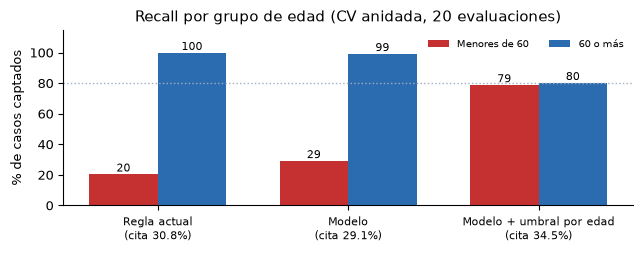

In [10]:
joven = lambda d: (d['age'] < 60).to_numpy()
reflejos = ['work_type', 'ever_married']   # la edad disfrazada (sección 8): children = menores, casado = mayores
modelo_sin = Pipeline([('prep', ColumnTransformer([prep.transformers[0],   # mismas numéricas; el resto de columnas se descarta
                                                   ('cat', OneHotEncoder(handle_unknown='ignore'), [x for x in cat if x not in reflejos])])),
                       ('m', familias[ganador][0].named_steps['m'])])


def medir_edad(cita, yv, j):
    return {'recall': cita[yv == 1].mean(), 'citados': cita.mean(),
            'recall_joven': cita[(yv == 1) & j].mean(), 'recall_mayor': cita[(yv == 1) & ~j].mean(),
            'citados_joven': cita[j].mean(), 'citados_mayor': cita[~j].mean()}


def por_edad(score, j, y_ref, s_ref, j_ref):
    """Un umbral por grupo de edad, cada uno con recall >= 0.80 en las predicciones de referencia."""
    tj, tm = umbral_recall(y_ref[j_ref], s_ref[j_ref]), umbral_recall(y_ref[~j_ref], s_ref[~j_ref])
    return np.where(j, score >= tj, score >= tm), tj, tm


def fold_sesgo(k, a, b):
    Xa, ya, Xb, yb = X_tr.iloc[a], y_tr.iloc[a].to_numpy(), X_tr.iloc[b], y_tr.iloc[b].to_numpy()
    ja, jb = joven(Xa), joven(Xb)
    interno = StratifiedKFold(5, shuffle=True, random_state=k)   # el mismo ciclo interno de la sección 4
    filas = [{'metodo': 'Regla actual', **medir_edad(regla(Xb), yb, jb)}]
    for nombre, m in [('Modelo', familias[ganador][0]), ('Sin reflejos de la edad', modelo_sin)]:
        g = GridSearchCV(m, familias[ganador][1], scoring='average_precision', cv=interno).fit(Xa, ya)
        oof_a = cross_val_predict(g.best_estimator_, Xa, ya, cv=interno, method='predict_proba')[:, 1]
        s = g.best_estimator_.predict_proba(Xb)[:, 1]
        filas.append({'metodo': nombre, **medir_edad(s >= umbral_recall(ya, oof_a), yb, jb)})
        filas.append({'metodo': nombre + ' + umbral por edad', **medir_edad(por_edad(s, jb, ya, oof_a, ja)[0], yb, jb)})
    return [{'fold': k, 'casos_joven': int(yb[jb].sum()), **f} for f in filas]


filas = Parallel(n_jobs=-1)(delayed(fold_sesgo)(k, a, b) for k, (a, b) in enumerate(externo.split(X_tr, y_tr)))
sesgo = pd.DataFrame([f for fs in filas for f in fs])
metodos = list(dict.fromkeys(sesgo['metodo']))
tabla_sesgo = sesgo.groupby('metodo').mean(numeric_only=True).drop(columns='fold').loc[metodos]
tabla_sesgo['recall_joven_sd'] = sesgo.groupby('metodo')['recall_joven'].std()
print(f"Casos menores de 60 por evaluación: {sesgo['casos_joven'].mean():.1f} (entrenamiento: {int(y_tr[joven(X_tr)].sum())} de {int(y_tr.sum())})")
print(tabla_sesgo.drop(columns='casos_joven').round(3).to_string())

# Peso de la edad sin los reflejos (SHAP del modelo lineal, como en la sección 8)
g_sin = GridSearchCV(modelo_sin, familias[ganador][1], scoring='average_precision', cv=interno).fit(X_tr, y_tr)
pre_s, lr_s = g_sin.best_estimator_.named_steps['prep'], g_sin.best_estimator_.named_steps['m']
Xs = pre_s.transform(X_tr)
Xs = Xs.toarray() if hasattr(Xs, 'toarray') else Xs
sv_s = shap.LinearExplainer(lr_s, shap.maskers.Independent(Xs, max_samples=len(Xs))).shap_values(Xs)
orig_s = np.array([variable(n) for n in pre_s.get_feature_names_out()])
imp_s = pd.Series({v: np.abs(sv_s[:, orig_s == v].sum(1)).mean() for v in dict.fromkeys(orig_s)})
print(f"Peso de la edad: {importancia['age'] / importancia.sum():.1%} con todas las variables, "
      f"{imp_s['age'] / imp_s.sum():.1%} sin los reflejos")

# Umbrales por edad con todo el entrenamiento (fuera de fold, como el umbral único de la sección 5)
j_tr, j_te = joven(X_tr), joven(X_te)
c_oof, t_joven, t_mayor = por_edad(oof, j_tr, ytr, oof, j_tr)
print(f'Umbral único {t:.3f} | por edad: menores de 60 {t_joven:.3f}, de 60 en adelante {t_mayor:.3f}')

# Prueba: segunda mirada, solo descriptiva. Los umbrales se fijaron arriba sin ella y no se ajustan con lo que muestre.
c_te = por_edad(s_te, j_te, ytr, oof, j_tr)[0]
cj, cm = int(yte[j_te].sum()), int(yte[~j_te].sum())
for nombre, cc in [('Umbral único', s_te >= t), ('Umbral por edad', c_te)]:
    print(f"Prueba, {nombre}: recall {cc[yte == 1].mean():.2f}, cita {cc.mean():.1%} | "
          f"menores de 60: {cc[(yte == 1) & j_te].sum()} de {cj} | 60 o más: {cc[(yte == 1) & ~j_te].sum()} de {cm}")

fig, ax = plt.subplots(figsize=(6.5, 2.6))
mostrar = ['Regla actual', 'Modelo', 'Modelo + umbral por edad']
xs = np.arange(len(mostrar))
for dx, col, lbl, color in [(-0.18, 'recall_joven', 'Menores de 60', ROJO), (0.18, 'recall_mayor', '60 o más', AZUL)]:
    barras = ax.bar(xs + dx, tabla_sesgo.loc[mostrar, col] * 100, 0.36, color=color, label=lbl)
    ax.bar_label(barras, fmt='%.0f', fontsize=8)
ax.set_xticks(xs, [f'{m}\n(cita {tabla_sesgo.loc[m, "citados"]:.1%})' for m in mostrar], fontsize=8)
ax.set(ylabel='% de casos captados', ylim=(0, 115), title='Recall por grupo de edad (CV anidada, 20 evaluaciones)')
ax.axhline(80, ls=':', color=GRIS, lw=1)
ax.legend(fontsize=7.5, frameon=False, loc='upper right', ncol=2)
plt.tight_layout(); plt.savefig('fig/f4_sesgo.png', dpi=200); plt.show()

# 3 decimales: la web muestra los mismos redondeos que la tabla
R['sesgo'] = {'cv': {m: tabla_sesgo.loc[m].round(3).to_dict() for m in metodos}, 'casos_joven_train': int(y_tr[j_tr].sum()),
              'peso_edad': importancia['age'] / importancia.sum(), 'peso_edad_sin_reflejos': imp_s['age'] / imp_s.sum(),
              'umbrales': {'unico': t, 'joven': t_joven, 'mayor': t_mayor},
              'oof': {'unico': medir_edad(oof >= t, ytr, j_tr), 'por_edad': medir_edad(c_oof, ytr, j_tr)},
              'prueba': {'casos_joven': cj, 'casos_mayor': cm,
                         **{k: {'recall': cc[yte == 1].mean(), 'citados': cc.mean(), 'joven': int(cc[(yte == 1) & j_te].sum()),
                                'mayor': int(cc[(yte == 1) & ~j_te].sum())}
                            for k, cc in [('unico', s_te >= t), ('por_edad', c_te)]}}}

**Lectura.**
- **El umbral por edad reduce el sesgo, y tiene precio.** En la CV anidada, el recall en menores de 60 pasa de 0.29 a **0.79** (la regla: 0.20) y en mayores baja de 0.99 a 0.80: los dos grupos quedan parejos y el recall total sigue en 0.80. A cambio, la lista crece del 29.1 % al **34.5 %** de los pacientes (la regla cita al 30.8 %): unas 540 citas más por cada 10 000 afiliados.
- **Quitar los reflejos de la edad no reduce el sesgo:** el recall en menores de 60 casi no cambia (0.31 frente a 0.29) y el peso de la edad sube del 63 % al 71 %. `work_type` y `ever_married` eran la edad disfrazada: al quitarlos, la edad se lleva su peso. El sesgo no está en esas columnas sino en el umbral único, que corta donde están casi todos los casos (los mayores).
- **La prueba confirma la dirección, no la magnitud.** Con los umbrales fijados solo con entrenamiento (0.268 para menores de 60 y 0.705 para 60 o más), en la prueba el modelo capta **5 de 12** casos menores de 60 en lugar de 2, y 36 de 38 mayores en lugar de 38, citando al 36.0 % en lugar del 29.0 %. 5 de 12 queda lejos del 0.79 de la CV: con 56 casos jóvenes en entrenamiento (unos 11 por evaluación; desviación estándar 0.12) el umbral de ese grupo es inestable. Es una segunda mirada a la prueba, solo descriptiva: no se ajustó nada con ella.
- **Decisión:** el modelo no cambia (la regla de selección se fijó antes). El umbral por edad se entrega como **una opción de operación más**, junto a la tabla de la sección 5: si la EPS prefiere que un joven con ACV tenga la misma probabilidad de ser citado que un mayor, usa dos umbrales y acepta citar unos 5 puntos más. El sesgo se reduce, no se elimina: la etiqueta sigue siendo histórica y hay pocos casos jóvenes.


## 10. Plan: de lo previsto a lo ejecutado
El plan original terminaba el 12 de noviembre; el calendario del curso se adelantó y las tareas de modelado se comprimieron en dos días (el piloto del 9 de octubre ya había comprobado que cabían: el proyecto completo corre en minutos). El diagrama alimenta la sección 6 del documento.

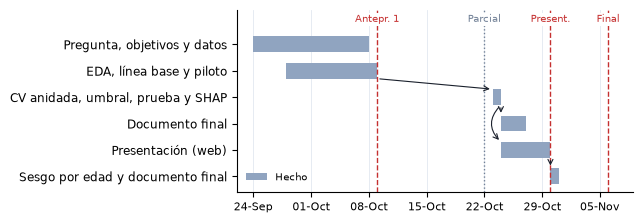

In [11]:
tareas = [  # (tarea, inicio, fin, índice de la tarea de la que depende, hecho)
    ('Pregunta, objetivos y datos', '2026-09-24', '2026-10-08', None, True),
    ('EDA, línea base y piloto', '2026-09-28', '2026-10-09', None, True),
    ('CV anidada, umbral, prueba y SHAP', '2026-10-23', '2026-10-24', 1, True),
    ('Documento final', '2026-10-24', '2026-10-27', 2, True),
    ('Presentación (web)', '2026-10-24', '2026-10-30', 2, True),
    ('Sesgo por edad y documento final', '2026-10-30', '2026-10-31', 4, True),
]
d = lambda s: mdates.date2num(pd.Timestamp(s))
fig, ax = plt.subplots(figsize=(6.5, 2.3))
for i, (tn, a, b, dep, hecho) in enumerate(tareas):
    ax.barh(i, d(b) - d(a), left=d(a), height=0.6, color='#90a4c0' if hecho else AZUL,
            label=('Hecho' if hecho else 'Pendiente') if tn == 'Pregunta, objetivos y datos' else None)
    if dep is not None:
        ax.annotate('', xy=(d(a), i - 0.3), xytext=(d(tareas[dep][2]), dep + 0.3), arrowprops=dict(
            arrowstyle='->', color='#1a202c', lw=0.8, connectionstyle=f'arc3,rad={0.5 if i - dep > 1 else 0}'))
ax.set_yticks(range(len(tareas)), [x[0] for x in tareas], fontsize=8.5)
ax.set(ylim=(len(tareas) - 0.4, -1.3), xlim=(d('2026-09-22'), d('2026-11-09')))
ax.legend(loc='lower left', fontsize=7.5, frameon=False)
for f, lbl, color, ls in [('2026-10-09', 'Antepr. 1', ROJO, '--'), ('2026-10-30', 'Present.', ROJO, '--'),
                          ('2026-11-06', 'Final', ROJO, '--'), ('2026-10-22', 'Parcial', '#718096', ':')]:
    ax.axvline(d(f), color=color, ls=ls, lw=1)
    ax.text(d(f), -0.85, lbl, color=color, fontsize=7.5, ha='center', bbox=dict(facecolor='white', edgecolor='none', pad=1))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.TH))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
ax.tick_params(axis='x', labelsize=8)
ax.grid(axis='x', color='#e2e8f0', lw=0.6)
ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('fig/f2_gantt.png', dpi=200); plt.show()

## 11. Conclusiones
1. **Datos:** 5 109 pacientes, 4.87 % con ACV; la edad es la señal dominante y hay señal real en P(y|X) (ROC-AUC 0.84).
2. **Resultado:** la regresión logística captó unos **2 casos más de cada 40** con las mismas citas que la regla (+1.75; 15 de 20 evaluaciones), o el mismo recall con **2 puntos menos de citas** (29 % en lugar de 31 %). En la prueba sellada: recall 0.80 y +1 caso (IC 95 %: 0 a 4).
3. **Lo interesante:** el PR-AUC, la métrica de negocio y la parsimonia señalaron tres modelos distintos, y las diferencias entre ellos caben en el ruido. Elegir con la métrica estándar habría escogido el modelo que más citas cuesta.
4. **Límites:** la mejora es moderada; `stroke` dice quién *ya tuvo* un ACV, no quién lo tendrá; la regla de la EPS es un supuesto; el modelo deja fuera a dos de cada tres casos menores de 60 años; y con 50 casos la prueba tiene un intervalo ancho.
5. **Sesgo por edad:** con un solo umbral el modelo capta 0.29 de los casos menores de 60. Un umbral por grupo de edad lo sube a 0.79 en la CV anidada (5 de 12 en la prueba) a cambio de citar al 34.5 % en lugar del 29.1 %. Quitar las variables que reflejan la edad no ayuda. Se entrega como opción de operación, no como reemplazo.
6. **Siguiente paso para producción:** reentrenar con datos de la EPS y una etiqueta de ACV posterior a una fecha de corte, con autorización de los titulares (Ley 1581 de 2012), y monitorear el recall por grupo de edad cada trimestre; con más casos jóvenes, probar un modelo propio para menores de 60.

Producto para quien decide: la **tabla de puntos de operación** (sección 5), la opción de umbral por edad (sección 9) y la lista ordenada por riesgo.

In [12]:
def limpio(o):   # numpy/pandas -> tipos de Python; NaN -> null (JSON válido)
    if isinstance(o, dict):
        return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray, pd.Series)):
        return [limpio(v) for v in o]
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if np.isnan(o) else round(float(o), 4)
    return o


with open('fig/resultados.json', 'w') as f:
    json.dump(limpio(R), f, ensure_ascii=False, indent=1)
print('Guardado fig/resultados.json')

Guardado fig/resultados.json
